In [2]:
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

## Генерация данных

In [3]:
n_samples = 100
true_w, true_b = 2.0, 3.0

X_numpy = np.random.randn(n_samples, 1).astype(np.float32)
y_numpy = (true_w * X_numpy + true_b + np.random.randn(n_samples, 1) * 0.1).astype(np.float32)

X_tensor = torch.from_numpy(X_numpy)
y_tensor = torch.from_numpy(y_numpy)

## Визуализация данных

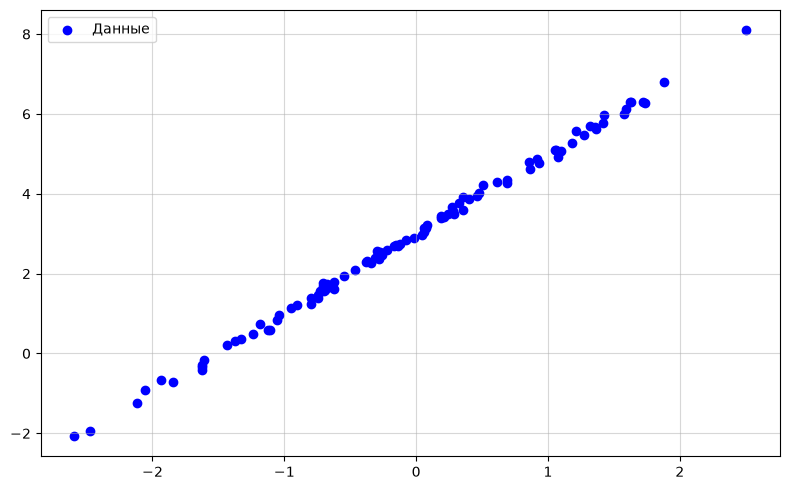

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(X_numpy, y_numpy, color='blue', label='Данные')
plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Параметры модели обучения

In [3]:
n_epochs = 1000
losses = []

model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=1e-2)

## Обучение модели

In [4]:
for epoch in range(n_epochs):
    y_pred = model(X_tensor)
    loss = criterion(y_pred, y_tensor)
    losses.append(loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if(epoch + 1) % 100 == 0:
        print(
            f"Эпоха {epoch + 1}: "
            f"loss={loss.item():.4f} | "
            f"w_manual: {model.weight.item():.4f} | "
            f"b_manual: {model.bias.item():.4f}"
        )

print("\nРЕЗУЛЬТАТЫ: ")
print(f"loss: {losses[-1]:.4f}")
print(f"true_w={true_w} | w_manual={model.weight.item():.4f}")
print(f"true_b={true_b} | b_manual={model.bias.item():.4f}")

Эпоха 100: loss=0.4731 | w_manual: 1.5789 | b_manual: 2.3954
Эпоха 200: loss=0.0262 | w_manual: 1.9089 | b_manual: 2.8921
Эпоха 300: loss=0.0102 | w_manual: 1.9825 | b_manual: 2.9784
Эпоха 400: loss=0.0096 | w_manual: 1.9978 | b_manual: 2.9942
Эпоха 500: loss=0.0096 | w_manual: 2.0008 | b_manual: 2.9972
Эпоха 600: loss=0.0096 | w_manual: 2.0014 | b_manual: 2.9978
Эпоха 700: loss=0.0096 | w_manual: 2.0016 | b_manual: 2.9979
Эпоха 800: loss=0.0096 | w_manual: 2.0016 | b_manual: 2.9979
Эпоха 900: loss=0.0096 | w_manual: 2.0016 | b_manual: 2.9979
Эпоха 1000: loss=0.0096 | w_manual: 2.0016 | b_manual: 2.9979

РЕЗУЛЬТАТЫ: 
loss: 0.0096
true_w=2.0 | w_manual=2.0016
true_b=3.0 | b_manual=2.9979


## График потерь

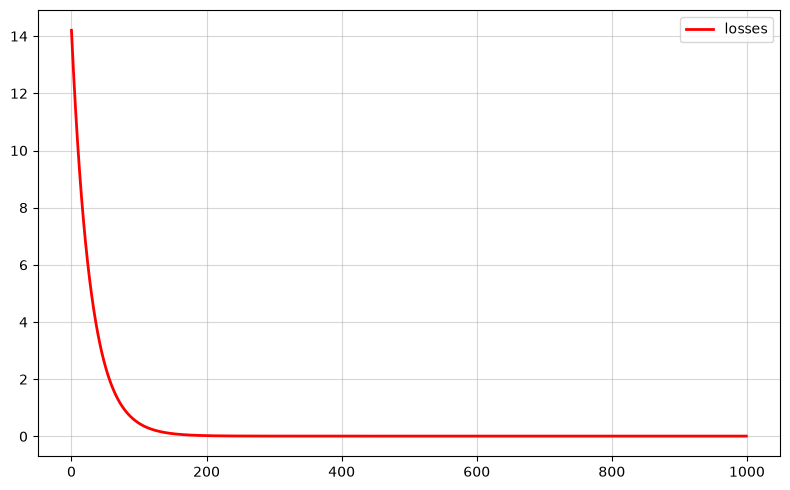

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(losses, label='losses', color='red', linewidth=2)
plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()